# Iris Multi-Class Classification Benchmark

**Task 1 | Beginner | Scikit-learn**

This notebook builds a reproducible Iris classification benchmark from the local `data.csv`. It compares Logistic Regression and Decision Tree using all four measurements, an 80/20 stratified holdout split, `StandardScaler`, and a fixed random seed.

The notebook reports accuracy, macro/weighted precision, recall and F1, per-species classification reports, confusion matrices, and multiclass one-vs-rest ROC curves. It also includes a two-feature decision-boundary visualization for interpretation.

## 1. Reproducibility and setup

Run this notebook from the project directory or its `notebooks` folder. Model preprocessing and evaluation functions live in `iris_classification.py`, so the notebook and command-line runner use the same implementation. No network access or hosted API is used.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Image, display

candidate_roots = [Path.cwd(), *Path.cwd().parents]
PROJECT_DIR = next((path for path in candidate_roots if (path / 'data.csv').is_file()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError('Could not locate data.csv. Open the notebook from the Iris project folder.')

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from iris_classification import (
    FEATURE_COLUMNS,
    TARGET_COLUMN,
    evaluate_models,
    load_dataset,
    run_benchmark,
    split_dataset,
)

sns.set_theme(style='whitegrid', context='notebook')
DATA_PATH = PROJECT_DIR / 'data.csv'
OUTPUT_DIR = PROJECT_DIR / 'outputs'
print(f'Project folder: {PROJECT_DIR.name}')
print(f'Dataset: {DATA_PATH.name}')

Project folder: Iris
Dataset: data.csv


## 2. Load and validate the dataset

The local file contains four numeric flower measurements and one categorical species target. The validation checks required fields, missing values, numeric finite features, and a multiclass target before training.

In [2]:
data = load_dataset(DATA_PATH)
print(f'Rows: {len(data)} | Features: {len(FEATURE_COLUMNS)} | Classes: {data[TARGET_COLUMN].nunique()}')
print(f'Exact duplicate rows retained: {data.duplicated().sum()}')
display(data.head())
display(data[list(FEATURE_COLUMNS)].describe().T.round(2))

Rows: 150 | Features: 4 | Classes: 3
Exact duplicate rows retained: 1


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


,count,mean,std,min,25%,50%,75%,max
sepal_length,150.0,5.84,0.83,4.3,5.1,5.80,6.4,7.9
sepal_width,150.0,3.06,0.44,2.0,2.8,3.00,3.3,4.4
petal_length,150.0,3.76,1.77,1.0,1.6,4.35,5.1,6.9
petal_width,150.0,1.20,0.76,0.1,0.3,1.30,1.8,2.5


The supplied file has 150 observations, balanced across three species, with no missing values. One exact repeated row is present. It is retained rather than removed so the benchmark evaluates the supplied data as-is.

## 3. Exploratory data analysis

The pairplot shows pairwise feature relationships by species. The correlation heatmap summarizes linear relationships among numeric measurements. These plots describe this small benchmark dataset; they are not a substitute for validation on independent data.

,observations
species,
setosa,50
versicolor,50
virginica,50


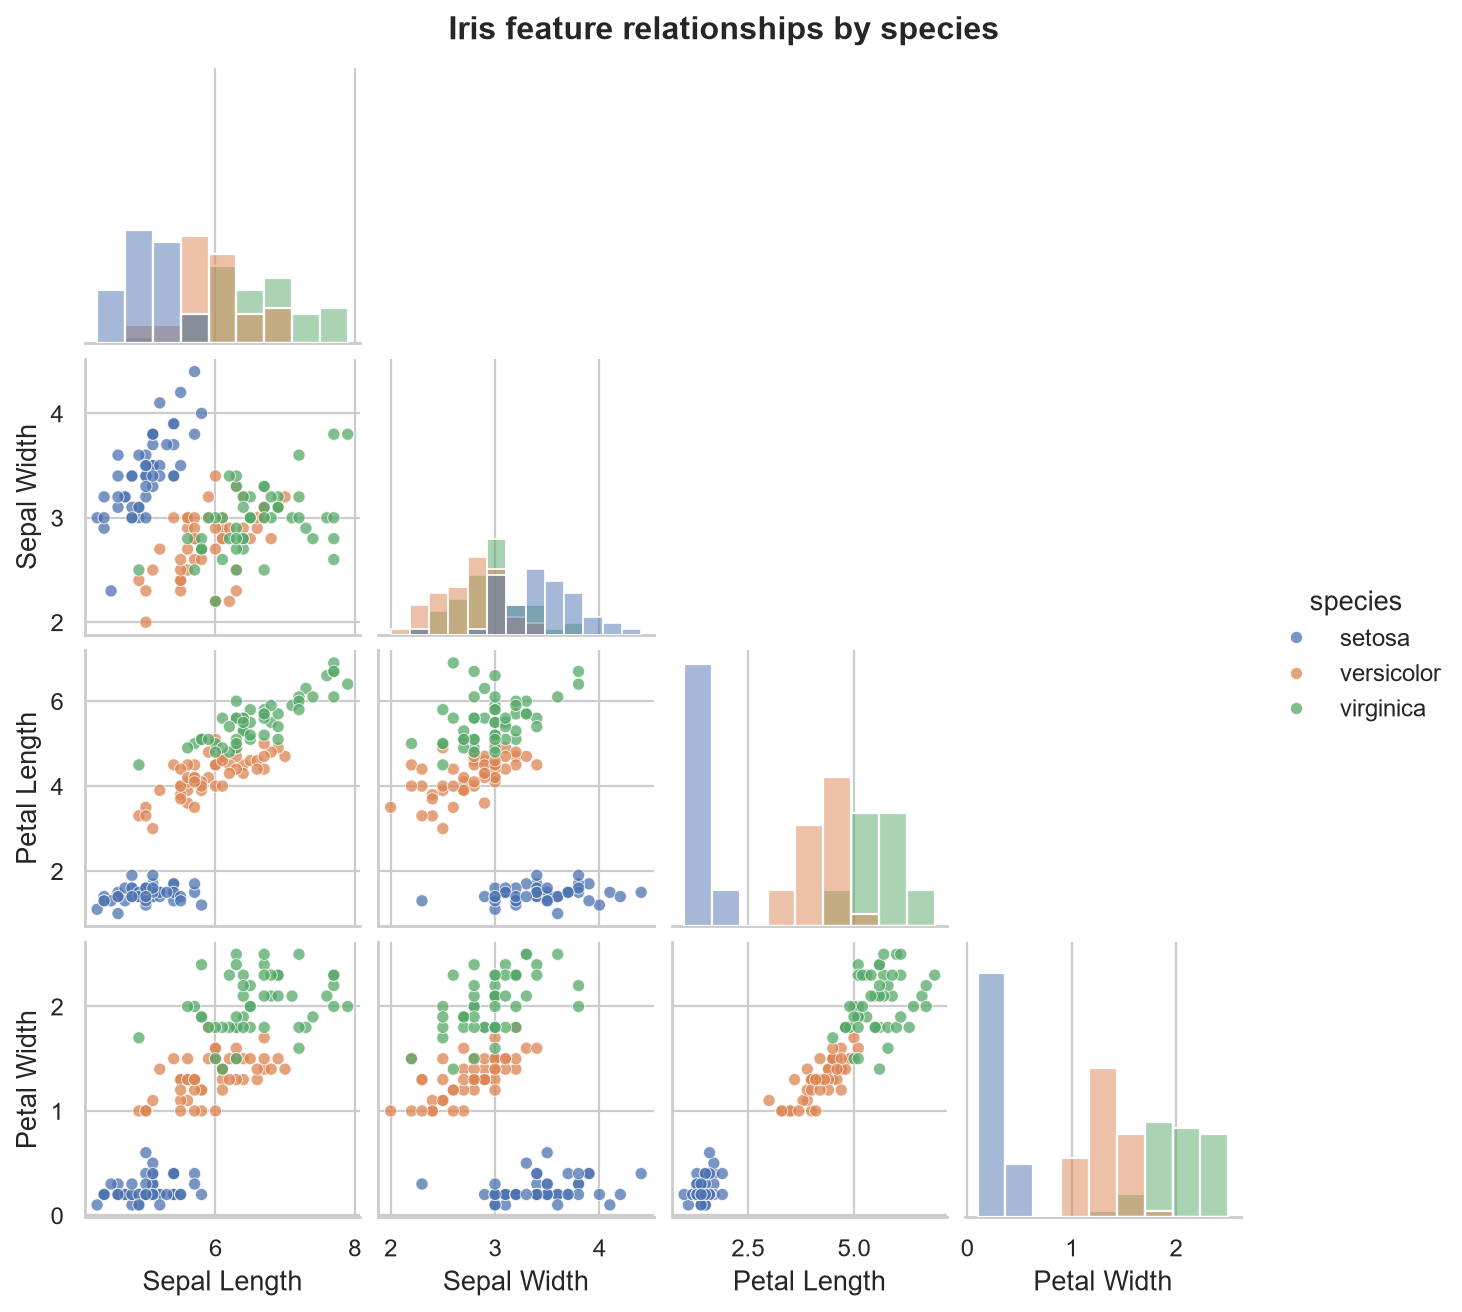

In [3]:
display(data[TARGET_COLUMN].value_counts().rename('observations').to_frame())
plot_data = data.rename(
    columns={feature: feature.replace('_', ' ').title() for feature in FEATURE_COLUMNS}
)
plot_features = [feature.replace('_', ' ').title() for feature in FEATURE_COLUMNS]
pair_plot = sns.pairplot(
    plot_data,
    vars=plot_features,
    hue=TARGET_COLUMN,
    corner=True,
    diag_kind='hist',
    height=2.0,
    plot_kws={'alpha': 0.75, 's': 30},
)
pair_plot.fig.suptitle('Iris feature relationships by species', y=1.02, weight='bold')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
pairplot_path = OUTPUT_DIR / 'eda_pairplot.png'
pair_plot.savefig(pairplot_path, dpi=160, bbox_inches='tight')
plt.close(pair_plot.fig)
display(Image(filename=str(pairplot_path)))

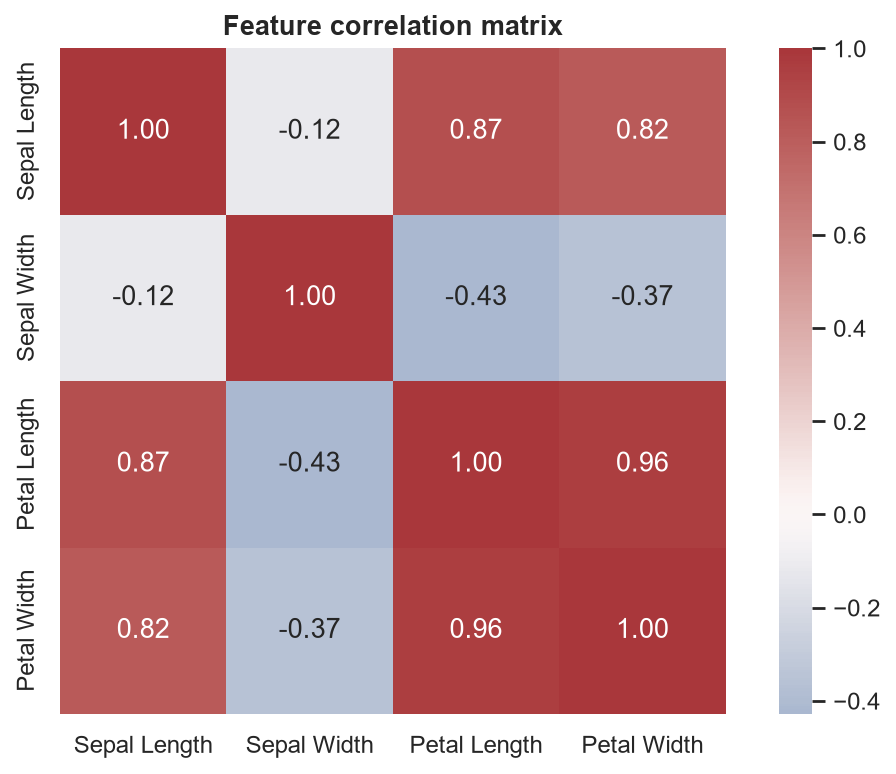

In [4]:
fig, ax = plt.subplots(figsize=(7, 5))
correlation_data = data[list(FEATURE_COLUMNS)].rename(
    columns=lambda column: column.replace('_', ' ').title()
)
sns.heatmap(
    correlation_data.corr(),
    annot=True,
    fmt='.2f',
    cmap='vlag',
    center=0,
    square=True,
    ax=ax,
)
ax.set_title('Feature correlation matrix', weight='bold')
fig.tight_layout()
correlation_path = OUTPUT_DIR / 'feature_correlation.png'
fig.savefig(correlation_path, dpi=160, bbox_inches='tight')
plt.close(fig)
display(Image(filename=str(correlation_path)))

## 4. Train/test split and leakage-safe preprocessing

A stratified split reserves 20% (30 rows) for final evaluation and preserves each species' share. `StandardScaler` is inside each scikit-learn pipeline, so it is fitted only on the training rows. Scaling is important for Logistic Regression; it does not materially affect tree splits, but keeps preprocessing explicit and the workflows comparable.

In [5]:
X_train, X_test, y_train, y_test = split_dataset(data)
print(f'Train: {len(X_train)} rows | Test: {len(X_test)} rows')
print('\nTraining class counts:')
display(y_train.value_counts().sort_index().rename('train_count').to_frame())
print('Test class counts:')
display(y_test.value_counts().sort_index().rename('test_count').to_frame())

Train: 120 rows | Test: 30 rows

Training class counts:


,train_count
species,
setosa,40
versicolor,40
virginica,40


Test class counts:


,test_count
species,
setosa,10
versicolor,10
virginica,10


## 5. Model benchmark

Both estimators use the same four input features, training rows, and held-out test rows. Macro averages weight each species equally; weighted averages account for class support. Multiclass ROC AUC uses one-vs-rest probabilities and macro averaging.

In [6]:
results, performance = evaluate_models(X_train, X_test, y_train, y_test)
display(performance.set_index('model').round(3))

,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,roc_auc_ovr_macro
model,,,,,,,,
Logistic Regression,0.933,0.933,0.933,0.933,0.933,0.933,0.933,0.997
Decision Tree,0.933,0.933,0.933,0.933,0.933,0.933,0.933,0.950


### Per-species classification reports

Each report shows precision, recall, F1-score, and support for each species, followed by macro and weighted averages.

In [7]:
for model_name, result in results.items():
    print(model_name)
    report = pd.DataFrame(result['classification_report']).T
    display(report.round(3))

Logistic Regression


,precision,recall,f1-score,support
setosa,1.000,1.000,1.000,10.000
versicolor,0.900,0.900,0.900,10.000
virginica,0.900,0.900,0.900,10.000
accuracy,0.933,0.933,0.933,0.933
macro avg,0.933,0.933,0.933,30.000
weighted avg,0.933,0.933,0.933,30.000


Decision Tree


,precision,recall,f1-score,support
setosa,1.000,1.000,1.000,10.000
versicolor,0.900,0.900,0.900,10.000
virginica,0.900,0.900,0.900,10.000
accuracy,0.933,0.933,0.933,0.933
macro avg,0.933,0.933,0.933,30.000
weighted avg,0.933,0.933,0.933,30.000


## 6. Confusion matrices

Rows represent actual species and columns represent predicted species. Diagonal counts are correct predictions; off-diagonal counts identify which classes were confused.

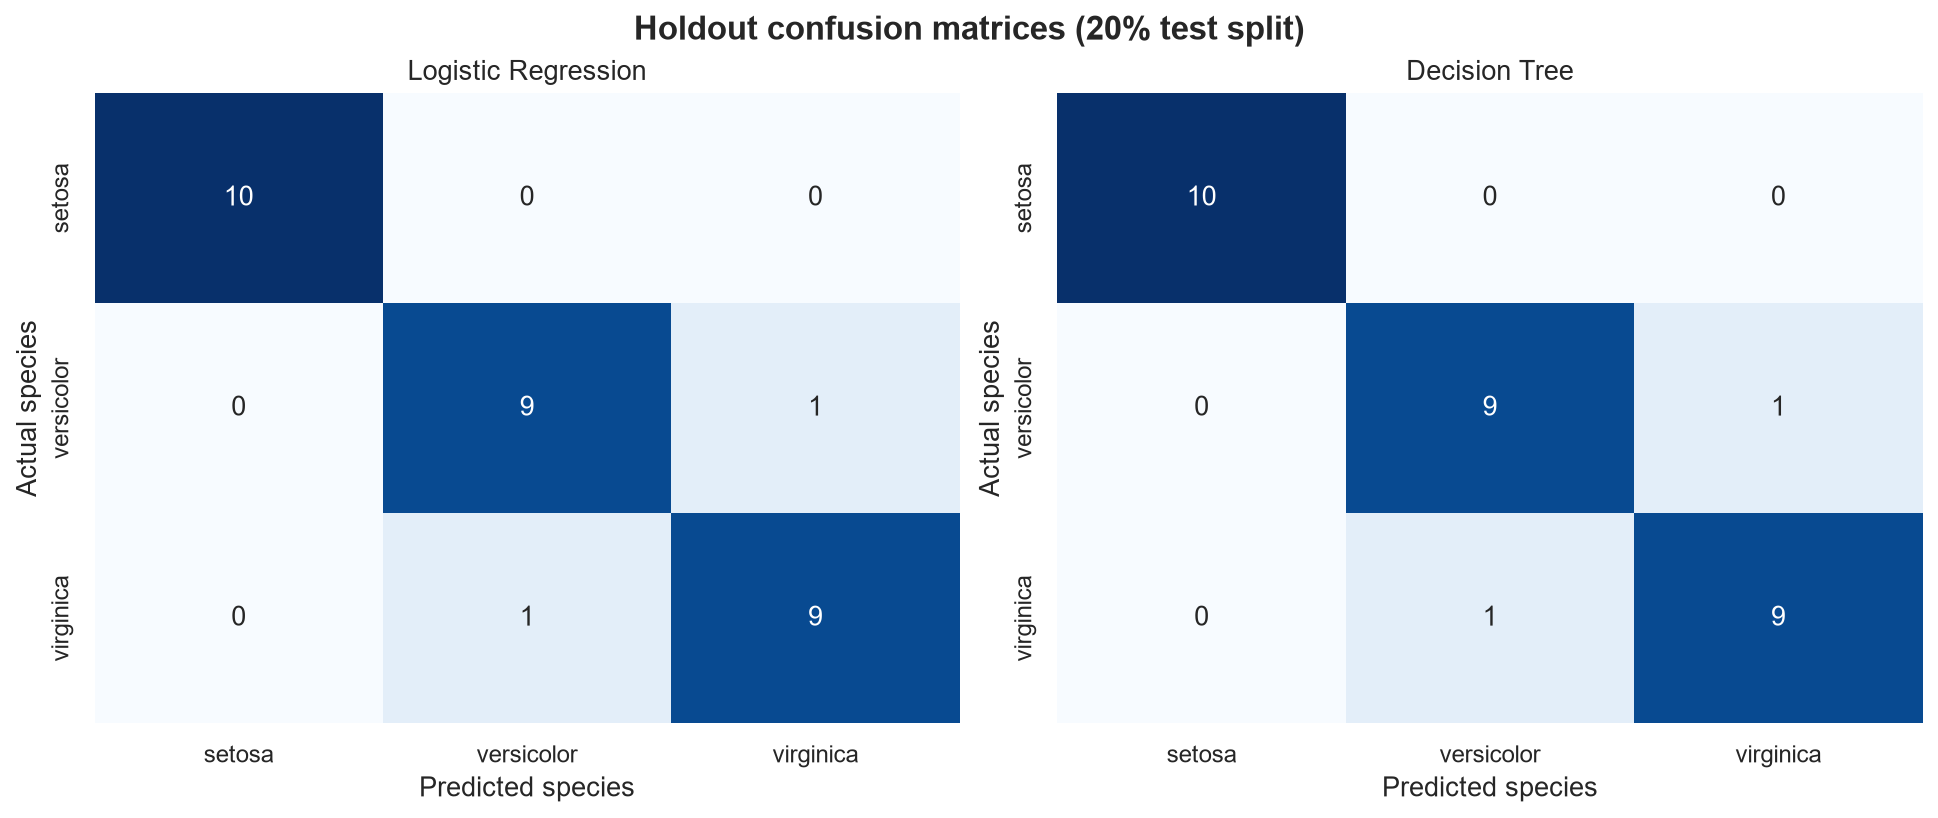

In [8]:
benchmark = run_benchmark(DATA_PATH, OUTPUT_DIR)
display(Image(filename=str(benchmark['artifacts']['confusion_matrices'])))

## 7. Multiclass ROC curves

Each curve treats one species as positive and the other two as negative. Solid lines are Logistic Regression and dashed lines are Decision Tree; the legend reports each model's macro one-vs-rest AUC. The dotted diagonal is the random-ranking reference.

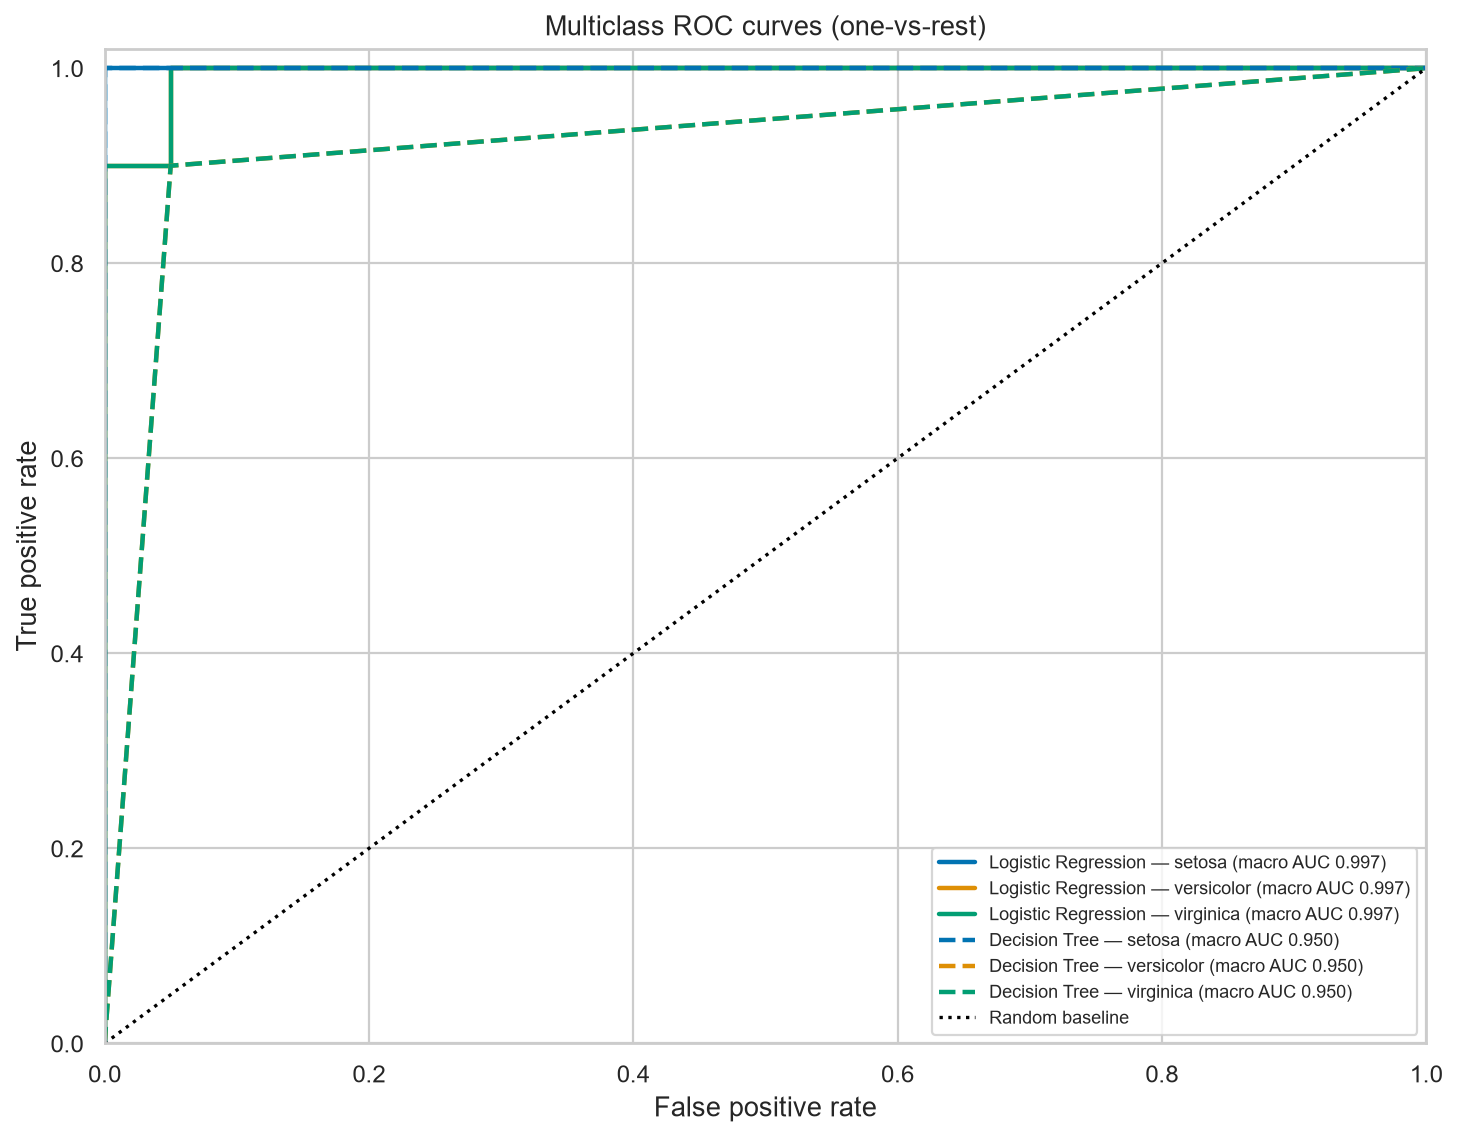

In [9]:
display(Image(filename=str(benchmark['artifacts']['roc_curves'])))

## 8. Performance comparison

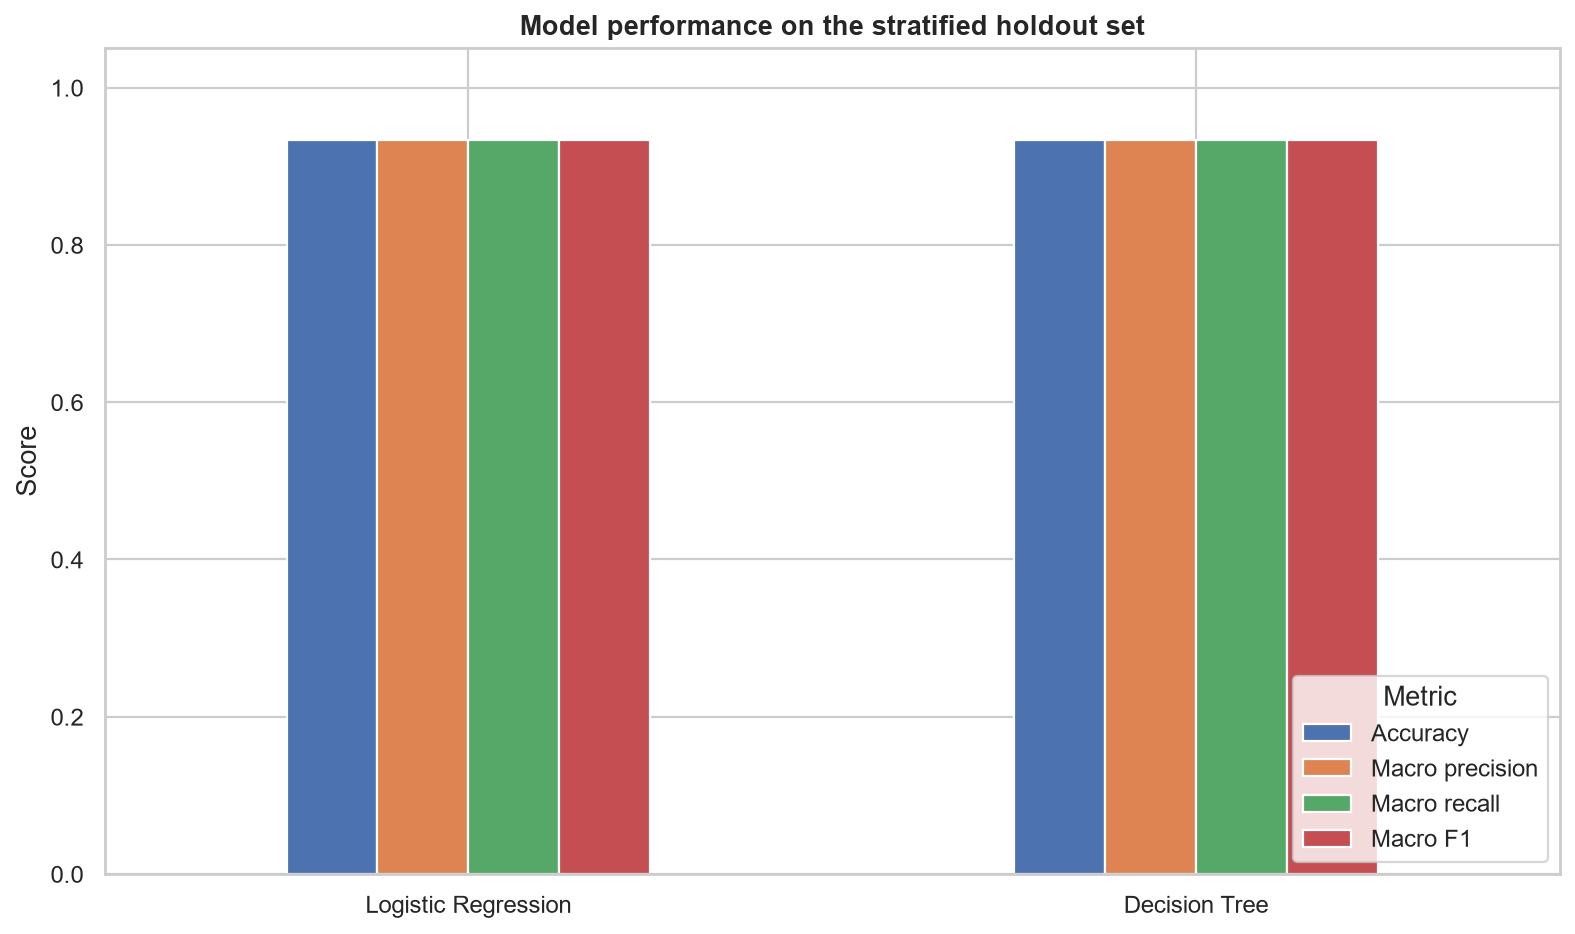

In [10]:
display(Image(filename=str(benchmark['artifacts']['performance_summary'])))

## 9. Two-feature decision-boundary illustration

This visualization retrains separate models using only sepal length and sepal width so the decision regions can be drawn in two dimensions. Test examples are colored by their true species; black rings indicate errors in these two-feature visual models. These models are not the four-feature benchmark models, and this plot is not used to select or tune them.

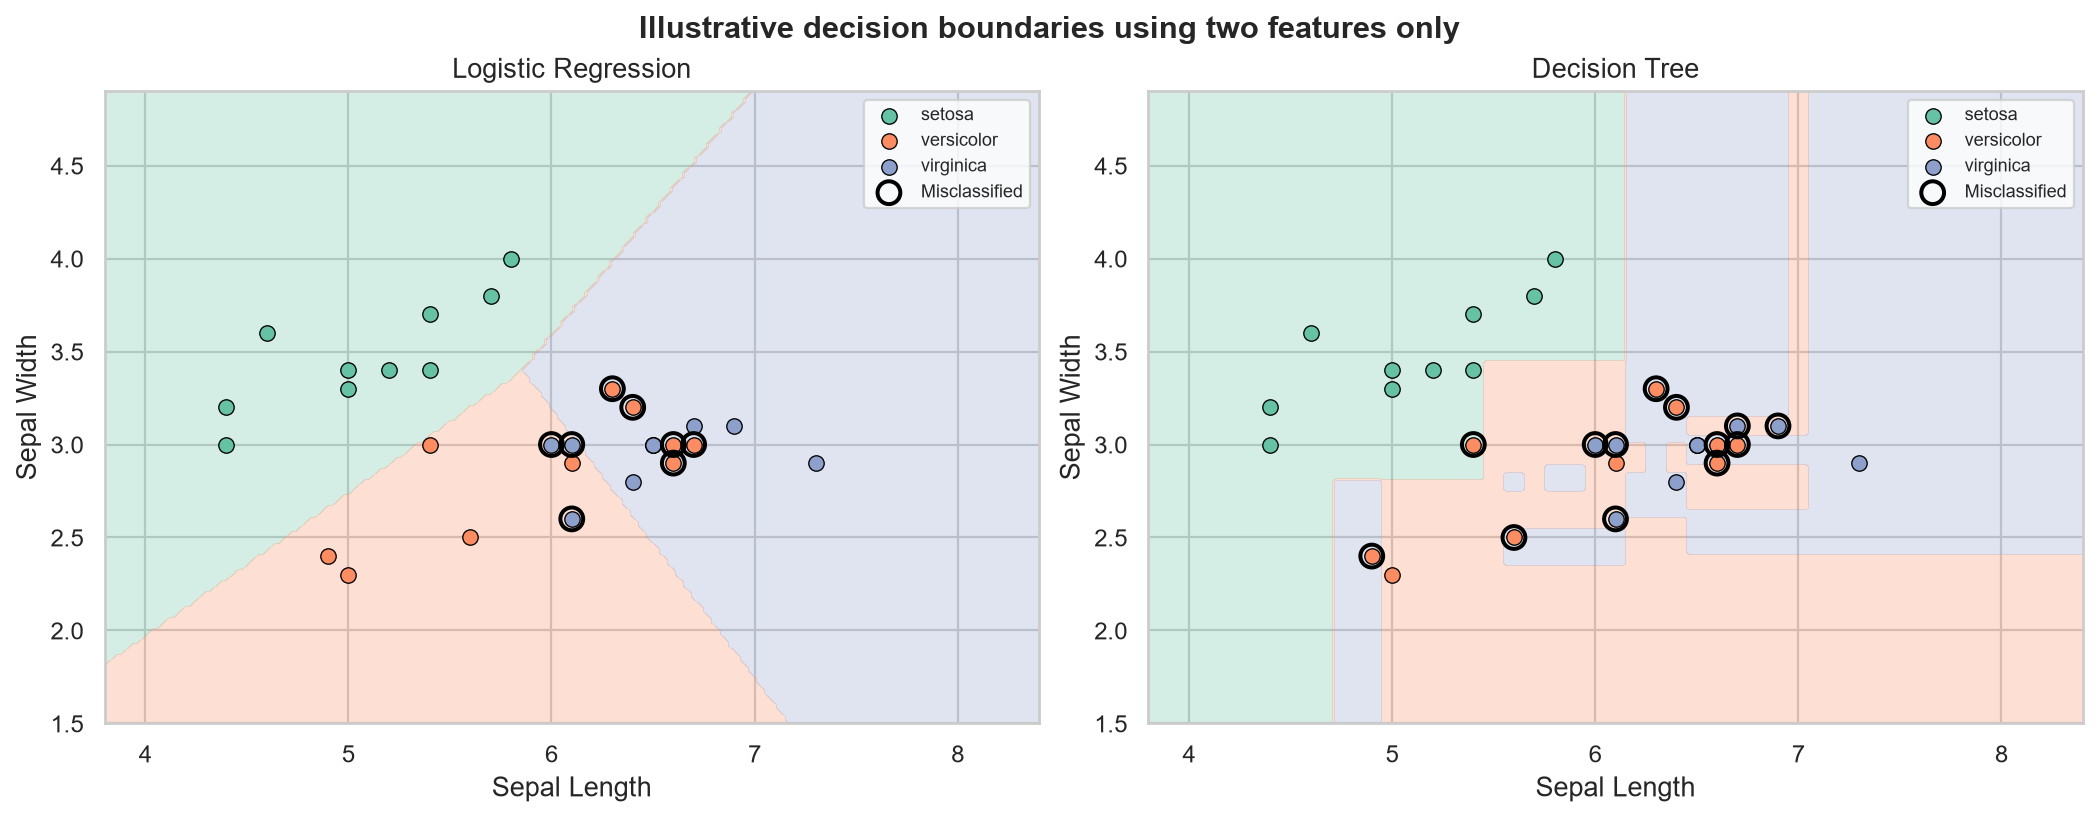

In [11]:
display(Image(filename=str(benchmark['artifacts']['decision_boundaries'])))

## 10. Summary and saved deliverables

The table below ranks the two models by macro F1 on the single holdout split. This is a descriptive benchmark result, not a statistically conclusive model selection.

In [12]:
display(benchmark['summary'].set_index('model').round(3))
print('\nSaved evaluation artifacts:')
for artifact in sorted(OUTPUT_DIR.iterdir()):
    print(f' - {artifact.name}')

,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,roc_auc_ovr_macro
model,,,,,,,,
Logistic Regression,0.933,0.933,0.933,0.933,0.933,0.933,0.933,0.997
Decision Tree,0.933,0.933,0.933,0.933,0.933,0.933,0.933,0.950



Saved evaluation artifacts:
 - benchmark_metadata.json
 - classification_reports.json
 - confusion_matrices.png
 - decision_boundaries.png
 - eda_pairplot.png
 - feature_correlation.png
 - performance_summary.csv
 - performance_summary.png
 - roc_curves.png


### Conclusion and limitations

The project completes the requested supervised classification workflow: local data validation, exploratory plots, stratified 80/20 splitting, standardized pipelines, two classifiers, classification metrics, confusion matrices, and ROC analysis. The saved PNG charts and CSV/JSON summaries are reproducible through the notebook or `python iris_classification.py`.

The test set contains only 30 observations, so one prediction changes accuracy by about 3.3 percentage points. The Iris dataset is small and curated; these results do not establish production readiness. Use cross-validation and representative independent data before drawing stronger conclusions.